# 2026-06-05 DNA Quantification — Portelite BDR (Qubit green channel)

Processes the Qubit fluorescence data recorded in
[`../lab_notebook/digitalized/2026-06-05_plaque-assay-r3-dna-extraction-quantification.md`](../lab_notebook/digitalized/2026-06-05_plaque-assay-r3-dna-extraction-quantification.md)
(source page p.31).

**Kit:** Portelite™ Fluorimetric DNA Quantitation Kit, Broad Dynamic Range (AAT Bioquest 17665).
Ex/Em 480/530 nm, green channel. Standards are calf-thymus DNA; the curve is fit by **linear
regression of RFU vs. concentration (ng/µL)** after subtracting the Std-0 blank RFU.

**Three sections:**
1. Build the standard curve (linear fit → slope, intercept, R²).
2. Convert each sample's reading to a DNA concentration (ng/µL).
3. Compute the DNA mass currently in each fridge tube (concentration × remaining volume).

## Key data note (read before trusting any number)
The sample columns in the .md are headed "Reading (ng/µL)" but the values are actually the **raw
green-channel fluorescence (RFU)**, on the *same scale as the standards* — e.g. Std 100 reads
16695 RFU while sample 8-2-2 reads 43887. (On p.31 the team headed the whole block
"Absorbance @540 nm".) Section 1 builds the curve; Section 2 turns these RFU into concentrations.

## Assumptions (flagged — change at the top if wrong)
- **`DILUTION_FACTOR = 1`** — no record of pre-diluting samples; the 10 µL taken into the assay is
  the same volume the standards use, and ~90/80 µL "left after aliquoting" implies a ~100 µL eluate
  drawn undiluted. If any sample was diluted before reading, set this factor accordingly.
- **Remaining volumes (from p.31 margin):** bacterial-genome extracts (Set A) ~**90 µL**;
  metagenomic extracts and mixes (Set B) ~**80 µL**. All stored at **4 °C**.
- Sample IDs / readings are transcribed verbatim from the .md (incl. `8-3-1` in Set A and the
  mix labels M1/M3/M4/M7 from the data table).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Tunable assay parameters -------------------------------------------------
DILUTION_FACTOR = 1          # multiply curve-derived conc by this if samples were pre-diluted
VOL_BACTERIAL_uL = 90.0      # Set A eluate remaining after Qubit aliquot (p.31 margin)
VOL_METAGENOMIC_uL = 80.0    # Set B sites + mixes remaining after Qubit aliquot (p.31 margin)
import os
DATE = '2026-06-05'
OUTPUT_DIR = 'output'         # figures saved here, named by date + content
os.makedirs(OUTPUT_DIR, exist_ok=True)
# -------------------------------------------------------------------------------

## Section 1 — Build the standard curve

Six-point series (the team used Component D = 100 ng/µL directly as the top standard). Subtract the
Std-0 blank RFU from every reading, then fit `RFU_corrected = slope · conc + intercept` by linear
regression. Report slope, intercept and R².

In [ ]:
# Standards (ng/uL, raw green-channel RFU) -- from the .md standards table (p.31)
standards = pd.DataFrame({
    'standard': ['Std 0 (blank)', 'Std 1', 'Std 3', 'Std 10', 'Std 30', 'Std 100'],
    'conc_ng_uL': [0.0, 1.0, 3.0, 10.0, 30.0, 100.0],
    'rfu':        [127.59, 325.63, 606.82, 1833.66, 5229.49, 16695.43],
})

BLANK_RFU = standards.loc[standards['conc_ng_uL'] == 0, 'rfu'].iloc[0]
standards['rfu_corrected'] = standards['rfu'] - BLANK_RFU

# Linear regression: rfu_corrected = slope * conc + intercept
slope, intercept = np.polyfit(standards['conc_ng_uL'], standards['rfu_corrected'], 1)
fit = slope * standards['conc_ng_uL'] + intercept
ss_res = np.sum((standards['rfu_corrected'] - fit) ** 2)
ss_tot = np.sum((standards['rfu_corrected'] - standards['rfu_corrected'].mean()) ** 2)
r_squared = 1 - ss_res / ss_tot

MAX_STD_CONC = standards['conc_ng_uL'].max()  # 100 ng/uL -> above this = extrapolated

print(f'Blank (Std 0) RFU      : {BLANK_RFU:.2f}')
print(f'Slope                  : {slope:.4f} RFU per ng/uL')
print(f'Intercept              : {intercept:.4f} RFU')
print(f'R^2                    : {r_squared:.6f}')
print(f'Top standard           : {MAX_STD_CONC:.0f} ng/uL '
      f'(readings above this are extrapolated)')
standards

Blank (Std 0) RFU      : 127.59
Slope                  : 165.6425 RFU per ng/uL
Intercept              : 33.4265 RFU
R^2                    : 0.999929
Top standard           : 100 ng/uL (readings above this are extrapolated)


,standard,conc_ng_uL,rfu,rfu_corrected
0,Std 0 (blank),0.0,127.59,0.00
1,Std 1,1.0,325.63,198.04
2,Std 3,3.0,606.82,479.23
3,Std 10,10.0,1833.66,1706.07
4,Std 30,30.0,5229.49,5101.90
5,Std 100,100.0,16695.43,16567.84


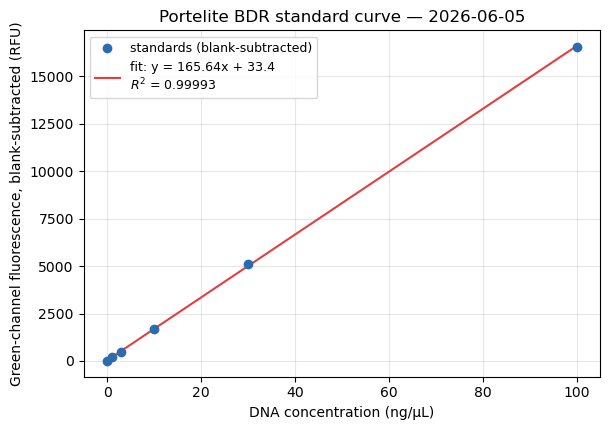

In [ ]:
# Conversion helper used by Section 2: invert the fitted line, apply dilution factor.
def rfu_to_conc(rfu):
    """Raw green-channel RFU -> DNA concentration (ng/uL) in the original tube."""
    return (np.asarray(rfu, dtype=float) - BLANK_RFU - intercept) / slope * DILUTION_FACTOR

# Plot the standard curve with the fit
fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.scatter(standards['conc_ng_uL'], standards['rfu_corrected'],
           color='#2b6cb0', zorder=3, label='standards (blank-subtracted)')
xline = np.linspace(0, MAX_STD_CONC, 100)
ax.plot(xline, slope * xline + intercept, color='#e53e3e', lw=1.5,
        label=f'fit: y = {slope:.2f}x + {intercept:.1f}\n$R^2$ = {r_squared:.5f}')
ax.set_xlabel('DNA concentration (ng/µL)')
ax.set_ylabel('Green-channel fluorescence, blank-subtracted (RFU)')
ax.set_title('Portelite BDR standard curve — 2026-06-05')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_standard-curve.png'),
            dpi=150, bbox_inches='tight')
plt.show()

## Section 2 — Sample DNA concentrations

Convert each raw reading to ng/µL via the fitted curve. `extrapolated = True` flags samples whose
concentration lands above the 100 ng/µL top standard (per the PI note, these are quoted off the
extrapolated line as long as they are not orders of magnitude above 100).

In [ ]:
# Raw green-channel readings transcribed from the .md (p.31). 'set' tags the volume bucket.
samples = pd.DataFrame([
    # Set A -- bacteria-genome extracts (Quick-DNA Miniprep, Zymo)
    ('8-5-2',  40827.88, 'A_bacterial'),
    ('8-2-2',  43887.14, 'A_bacterial'),
    ('10-9-2', 20917.70, 'A_bacterial'),
    ('9-6-2',  32384.09, 'A_bacterial'),
    ('9-2-1',  23232.52, 'A_bacterial'),
    ('8-3-2',  15622.18, 'A_bacterial'),
    ('10-10-2',23423.31, 'A_bacterial'),
    ('8-3-2',  26136.76, 'A_bacterial'),   # second 8-3-2 (was mis-transcribed as 8-3-1)
    ('6-3-2',  16999.92, 'A_bacterial'),
    ('9-2-2',  17097.18, 'A_bacterial'),
    # Set B -- metagenomic 2nd-batch re-quant (soil sites)
    ('#1', 429.84, 'B_metagenomic'),
    ('#3', 190.14, 'B_metagenomic'),
    ('#4', 353.60, 'B_metagenomic'),
    ('#7', 220.63, 'B_metagenomic'),
    # Set B -- batch-1 + batch-2 mixes
    ('M1 mix', 455.83, 'B_metagenomic'),
    ('M3 mix', 184.11, 'B_metagenomic'),
    ('M4 mix', 283.19, 'B_metagenomic'),
    ('M7 mix', 235.20, 'B_metagenomic'),
], columns=['sample', 'rfu', 'set'])

samples['conc_ng_uL'] = rfu_to_conc(samples['rfu'])
samples['extrapolated'] = samples['conc_ng_uL'] > MAX_STD_CONC

with pd.option_context('display.float_format', lambda v: f'{v:,.2f}'):
    print('Set A - bacteria-genome extracts')
    print(samples[samples['set'] == 'A_bacterial'][['sample', 'rfu', 'conc_ng_uL', 'extrapolated']]
          .to_string(index=False))
    print('\nSet B - metagenomic sites + mixes')
    print(samples[samples['set'] == 'B_metagenomic'][['sample', 'rfu', 'conc_ng_uL', 'extrapolated']]
          .to_string(index=False))

### Section 2 plots — concentration by sample group

Three bar charts with **independent y-axes** (bacterial reads ~100× higher than metagenomic, so a shared scale would flatten Set B to invisibility): bacteria-genome extracts, non-mix metagenomic sites, and batch-1 + batch-2 mixes. Hatched red-edged bars are **extrapolated** above the 100 ng/µL top standard.

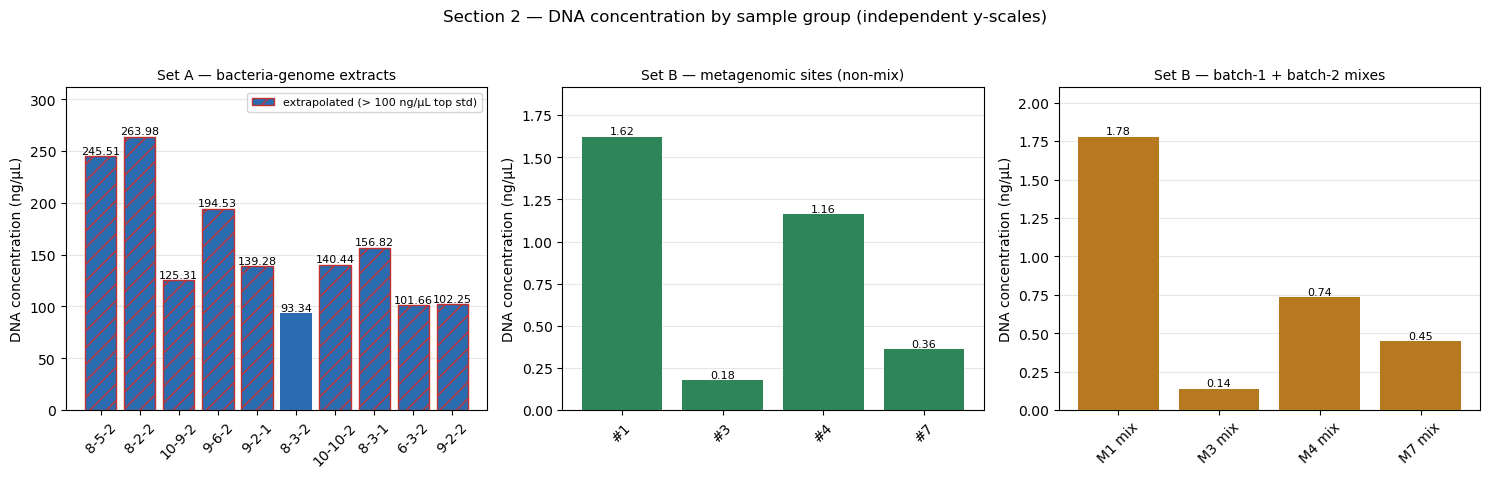

In [5]:
# Section 2 plots: DNA concentration per sample, one graph per group (independent y-scales)
from matplotlib.patches import Patch

is_mix = samples['sample'].str.contains('mix')
groups = [
    ('Set A — bacteria-genome extracts',
     samples[samples['set'] == 'A_bacterial'], '#2b6cb0'),
    ('Set B — metagenomic sites (non-mix)',
     samples[(samples['set'] == 'B_metagenomic') & (~is_mix)], '#2f855a'),
    ('Set B — batch-1 + batch-2 mixes',
     samples[is_mix], '#b7791f'),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (title, df, color) in zip(axes, groups):
    bars = ax.bar(df['sample'], df['conc_ng_uL'], color=color, zorder=3)
    for bar, extrap in zip(bars, df['extrapolated']):   # flag extrapolated bars
        if extrap:
            bar.set_hatch('//')
            bar.set_edgecolor('#c53030')
    for bar, val in zip(bars, df['conc_ng_uL']):        # value labels
        ax.text(bar.get_x() + bar.get_width() / 2, val, f'{val:.2f}',
                ha='center', va='bottom', fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel('DNA concentration (ng/µL)')
    ax.tick_params(axis='x', rotation=45)
    ax.margins(y=0.18)
    ax.grid(axis='y', alpha=0.3)

axes[0].legend(handles=[Patch(facecolor='#2b6cb0', hatch='//', edgecolor='#c53030',
                              label='extrapolated (> 100 ng/µL top std)')],
               fontsize=8, loc='upper right')
fig.suptitle('Section 2 — DNA concentration by sample group (independent y-scales)', y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_concentration-by-group.png'),
            dpi=150, bbox_inches='tight')
plt.show()

### Section 2 plots — recorded samples on the standard curve

The same three groups, but here each sample is placed **on the standard curve** at its (concentration, blank-subtracted RFU) position, alongside the standards (grey squares) and the fitted line. Per-group x/y ranges differ widely, so each panel is auto-scaled. For Set A the shaded band marks the **extrapolated region beyond the 100 ng/µL top standard**.

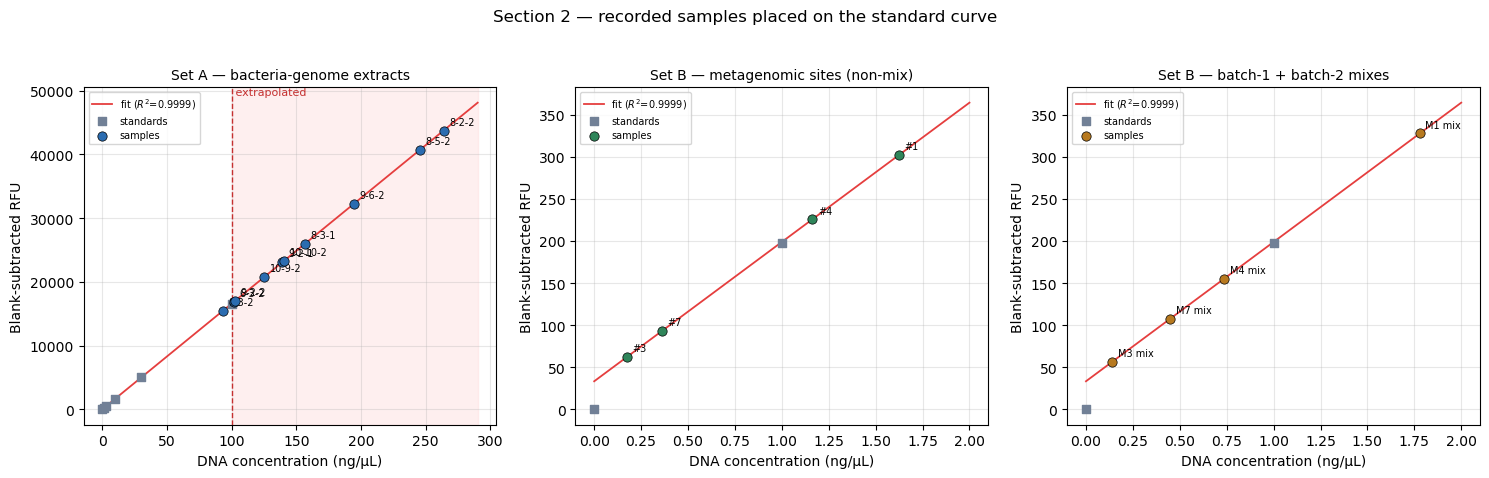

In [6]:
# Section 2: place each recorded sample on the standard curve, one graph per group
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
std_x = standards['conc_ng_uL'].values
std_y = standards['rfu_corrected'].values

for ax, (title, df, color) in zip(axes, groups):
    xmax = max(df['conc_ng_uL'].max() * 1.10, 2)
    xs = np.linspace(0, xmax, 100)
    ax.plot(xs, slope * xs + intercept, color='#e53e3e', lw=1.3, zorder=2,
            label=f'fit ($R^2$={r_squared:.4f})')
    m = std_x <= xmax                                   # standards in range, for reference
    ax.scatter(std_x[m], std_y[m], color='#718096', marker='s', s=35, zorder=3,
               label='standards')
    ax.scatter(df['conc_ng_uL'], df['rfu'] - BLANK_RFU, color=color, s=45, zorder=4,
               edgecolor='black', linewidth=0.5, label='samples')
    for _, r in df.iterrows():                          # label each point
        ax.annotate(r['sample'], (r['conc_ng_uL'], r['rfu'] - BLANK_RFU),
                    textcoords='offset points', xytext=(4, 4), fontsize=7)
    if xmax > MAX_STD_CONC:                             # mark extrapolated region
        ax.axvspan(MAX_STD_CONC, xmax, color='#fed7d7', alpha=0.4, zorder=1)
        ax.axvline(MAX_STD_CONC, color='#c53030', ls='--', lw=1, zorder=2)
        ax.text(MAX_STD_CONC, ax.get_ylim()[1], ' extrapolated', color='#c53030',
                fontsize=8, va='top', ha='left')
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('DNA concentration (ng/µL)')
    ax.set_ylabel('Blank-subtracted RFU')
    ax.legend(fontsize=7, loc='upper left')
    ax.grid(alpha=0.3)

fig.suptitle('Section 2 — recorded samples placed on the standard curve', y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_samples-on-standard-curve.png'),
            dpi=150, bbox_inches='tight')
plt.show()

## Section 3 — DNA mass currently in each fridge tube

`mass = concentration (ng/µL) × remaining volume (µL)`, reported in µg. Remaining volume is the
post-aliquot "left in tube" amount from the p.31 margin: **90 µL** for Set A (bacterial),
**80 µL** for Set B (metagenomic sites + mixes). All tubes are at **4 °C**.

> Assumption flag: the 80 µL margin note is written for "metagenomic samples" — applied here to the
> mixes as well, since they are metagenomic. Adjust `VOL_METAGENOMIC_uL` per-mix if they differ.

In [7]:
vol_map = {'A_bacterial': VOL_BACTERIAL_uL, 'B_metagenomic': VOL_METAGENOMIC_uL}
samples['remaining_vol_uL'] = samples['set'].map(vol_map)
samples['mass_ng'] = samples['conc_ng_uL'] * samples['remaining_vol_uL']
samples['mass_ug'] = samples['mass_ng'] / 1000.0

is_mix = samples['sample'].str.contains('mix')
out_cols = ['sample', 'conc_ng_uL', 'remaining_vol_uL', 'mass_ug', 'extrapolated']
with pd.option_context('display.float_format', lambda v: f'{v:,.3f}'):
    print('Set A - bacteria-genome extracts (90 uL each, 4 C)')
    print(samples[samples['set'] == 'A_bacterial'][out_cols].to_string(index=False))
    print('\nSet B - batch-1 + batch-2 mixes (80 uL each, 4 C)')
    print(samples[is_mix][out_cols].to_string(index=False))

totA = samples.loc[samples['set'] == 'A_bacterial', 'mass_ug'].sum()
totB = samples.loc[is_mix, 'mass_ug'].sum()
print(f'\nTotal recoverable DNA - Set A (bacterial): {totA:,.2f} ug')
print(f'Total recoverable DNA - Set B mixes: {totB:,.3f} ug')

Set A - bacteria-genome extracts (90 uL each, 4 C)
 sample  conc_ng_uL  remaining_vol_uL  mass_ug  extrapolated
  8-5-2     245.510            90.000   22.096          True
  8-2-2     263.979            90.000   23.758          True
 10-9-2     125.310            90.000   11.278          True
  9-6-2     194.534            90.000   17.508          True
  9-2-1     139.285            90.000   12.536          True
  8-3-2      93.341            90.000    8.401         False
10-10-2     140.437            90.000   12.639          True
  8-3-1     156.818            90.000   14.114          True
  6-3-2     101.658            90.000    9.149          True
  9-2-2     102.245            90.000    9.202          True

Set B - batch-1 + batch-2 mixes (80 uL each, 4 C)
sample  conc_ng_uL  remaining_vol_uL  mass_ug  extrapolated
M1 mix       1.780            80.000    0.142         False
M3 mix       0.139            80.000    0.011         False
M4 mix       0.738            80.000    0.059  

**Readout.** Set A bacterial genomes are in the ~90–260 ng/µL range (≈ 8–24 µg per tube), most
above the top standard so quoted by extrapolation. Set B metagenomic sites and mixes are ~1–2
ng/µL (≈ 0.1–0.15 µg per tube) — confirming the low-yield outcome and the plan to redo the
metagenomic extraction with smaller per-tube biomass.